# Unicycle circular path following (Lyapunov design)

Kinematic unicycle $\dot x = v\cos\theta,\ \dot y = v\sin\theta,\ \dot\theta = \omega$ with constant $v>0$, circle of radius $R$ centred at the origin, travelled counter-clockwise. Errors:
- cross-track error $e = \sqrt{x^2+y^2} - R$
- heading error $\tilde\theta = \theta - \theta_p$, with $\theta_p = \operatorname{atan2}(y,x) + \pi/2$ the tangent direction.

Error kinematics: $\dot e = -v\sin\tilde\theta$, $\quad\dot{\tilde\theta} = \omega - \dfrac{v\cos\tilde\theta}{R+e}$. Lyapunov function $V = \tfrac12 e^2 + \tfrac{1}{k_y}(1-\cos\tilde\theta)$.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np, sympy as sp, matplotlib.pyplot as plt
from IPython.display import Math, display
from src.symbolic.lyapunov import derive_circular_path_following
from src.experiments import load, simulate_unicycle

res = derive_circular_path_following()
display(Math(r"\omega = " + sp.latex(res["omega_law"])))
display(Math(r"\dot V = " + sp.latex(res["V_dot_sub"])))
display(Math(r"J_{(0,0)} = " + sp.latex(res["J_origin"]) + r",\qquad J_{(0,\pi)} = " + sp.latex(res["J_reverse"])))
res["checks"]

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

{'V_dot_is_minus_ktheta_over_ky_sin2': True,
 'origin_is_equilibrium': True,
 'reverse_is_equilibrium': True,
 'origin_hurwitz': True,
 'reverse_is_saddle': True}

**What this proves.** Take a sublevel set $\Omega_c = \{V\le c\}$ with $c < \tfrac12 R^2$: it is compact, forward invariant and keeps $|e| < R$, i.e. away from the singularity at the centre of the circle. By LaSalle, trajectories starting in $\Omega_c$ converge to the largest invariant set in $\{\sin\tilde\theta = 0\}$, which is $\{(0,0)\} \cup \{(0,\pi)\}$. The second point (driving the circle clockwise) is a saddle (negative determinant of the linearisation), so it attracts only a measure-zero set of initial conditions; if moreover $c < 2/k_y$ it is not in $\Omega_c$ and every trajectory in $\Omega_c$ converges to $(0,0)$.

The result is **not global**. The initial condition below ($e(0) = 1.5$ m, $\tilde\theta(0) = \pi/4$, $V(0) \approx 1.42 > \tfrac12R^2 = 1.125$) lies outside the certified set: its convergence is observed, not guaranteed.

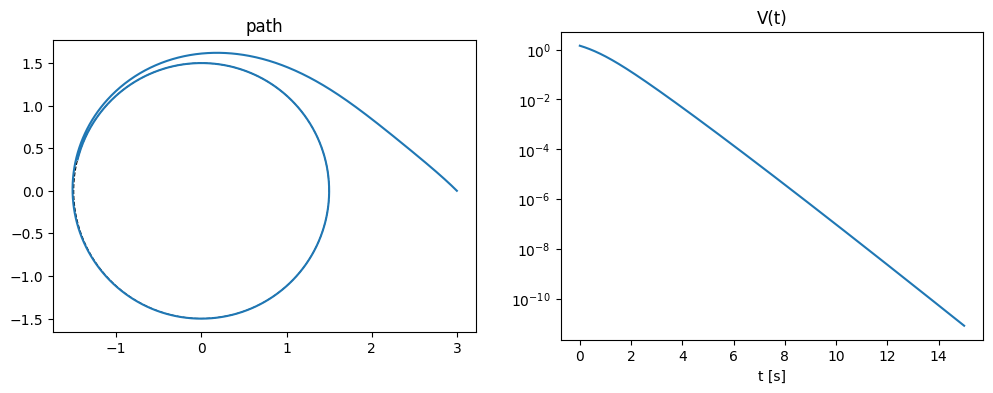

V(0) = 1.418  (certified set: V < 1.125),  final |e| = 2.9e-06 m


In [2]:
cfg = load("unicycle")
df = simulate_unicycle(cfg)
R = cfg["control"]["R"]
th = np.linspace(0, 2*np.pi, 300)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(R*np.cos(th), R*np.sin(th), "k--", lw=0.8); ax[0].plot(df.x, df.y); ax[0].set_aspect("equal"); ax[0].set_title("path")
ax[1].semilogy(df.t, df.V); ax[1].set_title("V(t)"); ax[1].set_xlabel("t [s]")
plt.show()
print(f"V(0) = {df.V.iloc[0]:.3f}  (certified set: V < {0.5*R**2:.3f}),  final |e| = {abs(df.e.iloc[-1]):.1e} m")